In [40]:
#import the packages
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp #solves the ODEs numerically
from scipy.optimize import brentq, curve_fit #root finding and curve fitting

In [41]:
#the parameters
#all these values are the standard textbook parameters for the
#Morris-Lecar model
healthy = dict(
    C = 20.0, #membrane capacitance
    g_L = 2.0, V_L = -60.0, #leak: conductance and its eq. voltage
    g_Ca = 4.0, V_Ca = 120.0, #calcium: conductance and eq. voltage
    g_K = 8.0, V_K = -84.0, #potassium: conductance and eq. voltage
    V1 = -1.2, V2 = 18.0, #shape of the Ca channel opening curve m_inf(V)
    V3 = 12.0, V4 = 17.4, #shape of the K channel opening curve w_inf(V)
    phi = 1/15, #how slow the K channels are (smaller = slower)
)
print(healthy)

{'C': 20.0, 'g_L': 2.0, 'V_L': -60.0, 'g_Ca': 4.0, 'V_Ca': 120.0, 'g_K': 8.0, 'V_K': -84.0, 'V1': -1.2, 'V2': 18.0, 'V3': 12.0, 'V4': 17.4, 'phi': 0.06666666666666667}


In [42]:
#channel opening curves

def m_inf(V, p):
  #fraction of Ca2+ channels open at voltage V
  #Ca2+ channels are so fast we can assume they are always at this value
  #(time-scale separation)
  #tanh makes an S-shaped curve, 0.5*(1 + tanh(..)) rescales it to go from 0 to 1
  #V1 = voltage where half the channels are open, V2 = how steep the curve is
  return 0.5 * (1 + np.tanh((V - p["V1"])/p["V2"]))

def w_inf(V, p):
  #fraction of K+ channels that WOULD be open at voltage V if we waited long enough
  #this is the "target" that w slowly moves toward
  #V3 = voltage where half are open, V4 = steepness
  return 0.5 * (1 + np.tanh((V - p["V3"])/p["V4"]))

def tau_w(V, p):
  #sets how slowly w moves toward its target at volatge V
  #cosh is always >= 1, so 1/cosh is b/w 0 and 1
  return 1/np.cosh((V - p["V3"])/(2 * p["V4"]))

#the 2 differential equations

def derivs(V, w, I, p):
  #inputs: voltage V, K+ open fraction w, input current I, parameter dict p
  #returns how fast V and w are changing rn (dV/dt, dw/dt)

  #each current = conductance X (V - that ion's equilibrium volatge)
  I_L = p["g_L"] * (V - p["V_L"]) #leak: always open, pulls V toward -60 mV
  I_Ca = p["g_Ca"] * m_inf(V, p) * (V - p["V_Ca"]) #calcium: instant, pushes V up towards +120 mV
  I_K = p["g_K"] * w * (V - p["V_K"]) #potassium: slow (uses w), pulls V down towards -84 mV

  #capacitor equation: C dV/dt = input current - all ionic currents
  dV = (I - I_L - I_Ca - I_K)/p["C"]

  #w moves towards its target w_inf(V)
  #if w < w_inf, the bracket is positive, so w increases (and vice versa)
  #phi and tau_w sets how fast
  dw = p["phi"] * (w_inf(V, p) - w)/tau_w(V, p)

  return dV, dw

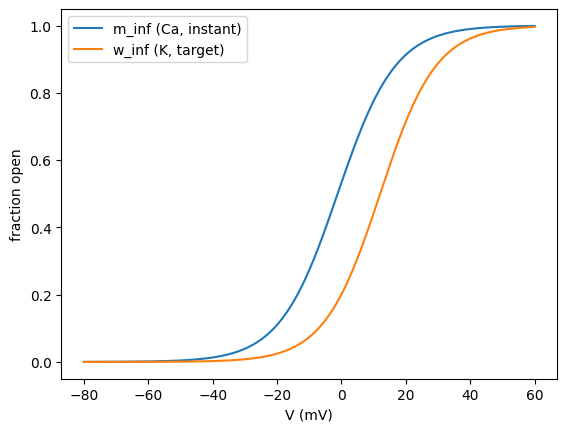

(np.float64(0.05227340796035662), np.float64(6.823734132264076e-05))


In [43]:
#test: look at the channel opening curves

V = np.linspace(-80, 60, 300) #300 voltage values from -80 to +60 mV

plt.plot(V, m_inf(V, healthy), label = "m_inf (Ca, instant)") #Ca2+ opening curve
plt.plot(V, w_inf(V, healthy), label = "w_inf (K, target)") #K+ target curve
plt.xlabel("V (mV)")
plt.ylabel("fraction open")
plt.legend()
plt.show()

#rates of change at V = -60 mV, w = 0, with no input current (I = 0)
#prints (dV/dt, dw/dt)
print(derivs(-60.0, 0.0, 0.0, healthy))

In [44]:
def simulate(p, I, T=600.0, y0=(-60.0, 0.0)):
  #simulate the neuron with a constant input current I for T milliseconds
  #p = parameter dictionary, y0 = starting (V, w)
  #returns time points t, voltage V and K+ fraction w at each time

  def f(t, y):
    #solve_ivp needs a function of (time, state) that returns the derivativres
    #y is the state [V, w], we unpack it and call derivs
    V, w = y
    return derivs(V, w, I, p)

  #integrate from t = 0 to t = T starting at y0
  #max_step = 0.5 ms stops the solver from stepping over a fast spike
  #rtol and atol set how accurate each step must be
  sol = solve_ivp(f, (0, T), y0, max_step = 0.5, rtol = 1e-6, atol = 1e-8)

  #sol.t = time points, sol.y[0] = V values, sol.y[1] = w values
  return sol.t, sol.y[0], sol.y[1]

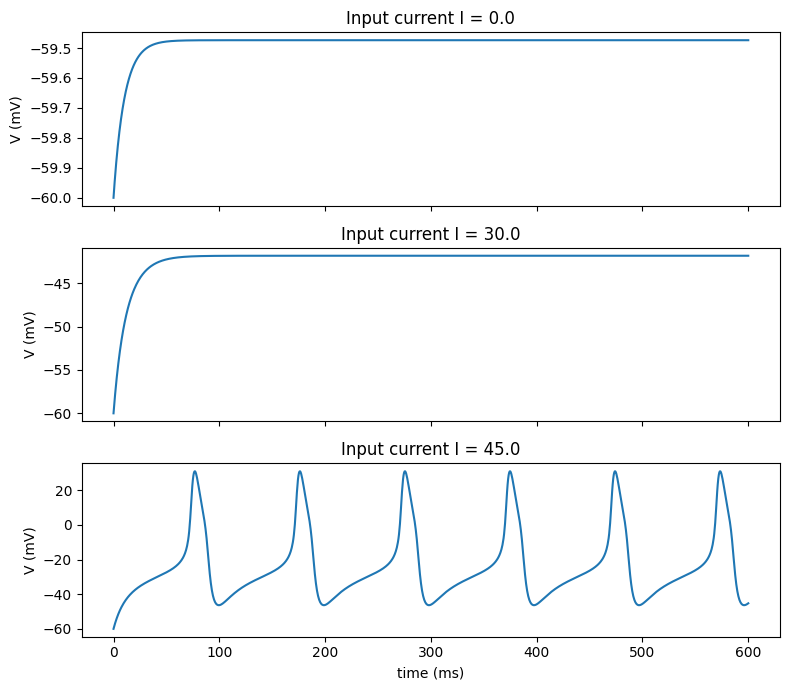

In [45]:
#run the neuron at 3 different input currents and plot the voltage

fig, ax = plt.subplots(3, 1, figsize = (8, 7), sharex = True) #3 stacked plots, same time axis

for i, I in enumerate([0.0, 30.0, 45.0]): #loop over 3 input currents
  t, V, w = simulate(healthy, I) #simulate 600 ms at this input
  ax[i].plot(t, V) #voltage over time
  ax[i].set_ylabel("V (mV)")
  ax[i].set_title(f"Input current I = {I}")

ax[2].set_xlabel("time (ms)")
fig.tight_layout()
plt.show()

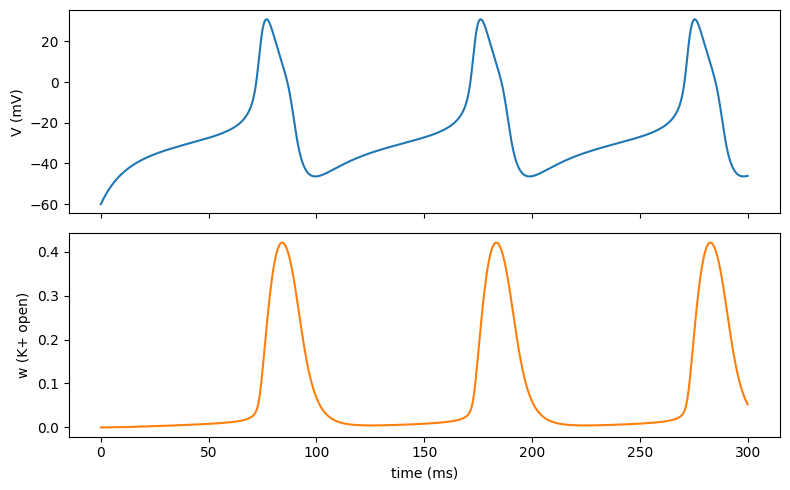

In [46]:
#zoom in on the spiking case to see hoe V and w move together

t, V, w = simulate(healthy, 45.0, T = 300.0) #300 ms at I = 45

fig, ax = plt.subplots(2, 1, figsize = (8, 5), sharex = True)
ax[0].plot(t, V) #voltage
ax[0].set_ylabel("V (mV)")
ax[1].plot(t, w, color = "C1") #K+ open fraction
ax[1].set_ylabel("w (K+ open)")
ax[1].set_xlabel("time (ms)")
fig.tight_layout()
plt.show()

In [47]:
def v_nullcline(V, I, p):
    #w values where dV/dt = 0, for each voltage V and input current I
    #comes from setting the voltage equation to zero and solving for w
    top = I - p["g_L"] * (V - p["V_L"]) - p["g_Ca"] * m_inf(V, p) * (V - p["V_Ca"])
    bottom = p["g_K"] * (V - p["V_K"])
    return top / bottom

def w_nullcline(V, p):
    #w values where dw/dt = 0: w sits exactly at its target
    return w_inf(V, p)

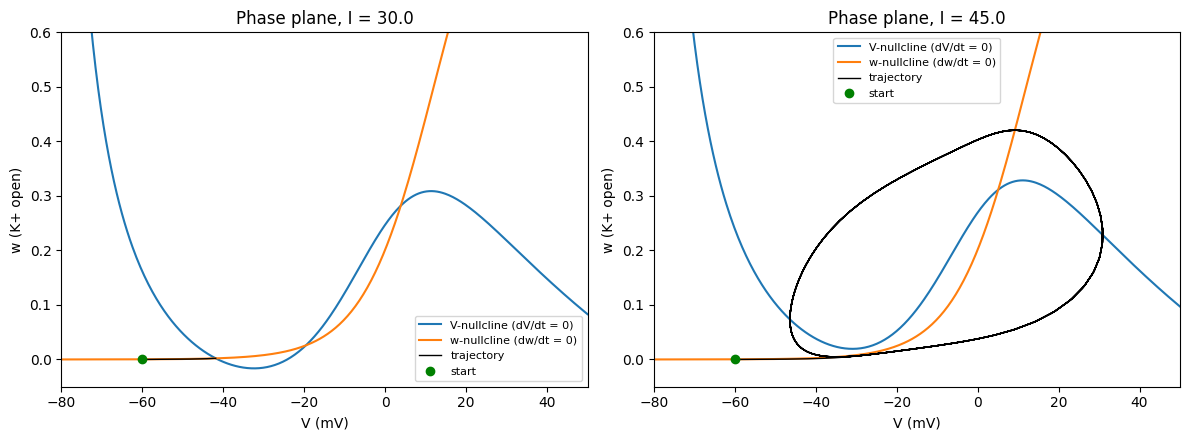

In [48]:
def plot_phase_plane(I, ax):
    #draw both nullclines and the simulated trajectory for input current I on axis ax
    V = np.linspace(-80, 50, 400)                          #voltage range for the curves

    ax.plot(V, v_nullcline(V, I, healthy), label="V-nullcline (dV/dt = 0)")
    ax.plot(V, w_nullcline(V, healthy), label="w-nullcline (dw/dt = 0)")

    t, Vt, wt = simulate(healthy, I)                       #simulate from rest (-60, 0)
    ax.plot(Vt, wt, "k", lw=1, label="trajectory")         #path of (V, w) over time
    ax.plot(Vt[0], wt[0], "go", label="start")             #green dot = starting point

    ax.set_xlim(-80, 50)
    ax.set_ylim(-0.05, 0.6)
    ax.set_xlabel("V (mV)")
    ax.set_ylabel("w (K+ open)")
    ax.set_title(f"Phase plane, I = {I}")
    ax.legend(fontsize=8)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))   #two plots side by side
plot_phase_plane(30.0, ax[0])                     #below threshold
plot_phase_plane(45.0, ax[1])                     #above threshold
fig.tight_layout()
plt.show()

In [49]:
def I_ion(V, p):
    #total ionic current at voltage V when w is at its steady value w_inf(V)
    #equilibria are where this equals the input current I
    return (p["g_L"] * (V - p["V_L"])
            + p["g_Ca"] * m_inf(V, p) * (V - p["V_Ca"])
            + p["g_K"] * w_inf(V, p) * (V - p["V_K"]))

def equilibria(p, I):
    #find all equilibria (V, w) for input current I.
    Vgrid = np.linspace(-90, 60, 3001)            #many voltages to check
    g = I - I_ion(Vgrid, p)                       #zero exactly at an equilibrium
    roots = []
    for i in range(len(Vgrid) - 1):
        if np.sign(g[i]) != np.sign(g[i + 1]):    #sign change = a root lies between these two points
            V = brentq(lambda v: I - I_ion(v, p), Vgrid[i], Vgrid[i + 1])   # zoom in on the root
            roots.append((V, w_inf(V, p)))        #at equilibrium, w = w_inf(V)
    return roots

def jacobian(V, w, I, p, h=1e-6):
    #2x2 matrix of partial derivatives at (V, w), found by nudging each variable by h.
    f0 = np.array(derivs(V, w, I, p))                              #derivatives at the point
    J = np.zeros((2, 2))
    J[:, 0] = (np.array(derivs(V + h, w, I, p)) - f0) / h          #column 1: effect of nudging V
    J[:, 1] = (np.array(derivs(V, w + h, I, p)) - f0) / h          #column 2: effect of nudging w
    return J

def classify(eigs):
    #label an equilibrium from the real parts of its eigenvalues.
    re = np.real(eigs)
    if np.all(re < 0):
        return "stable"
    if np.all(re > 0):
        return "unstable"
    return "saddle"

In [50]:
#find and classify every equilibrium at I = 30 and I = 45
for I in [30.0, 45.0]:
    print(f"- I = {I} -")
    for (V, w) in equilibria(healthy, I):
        eigs = np.linalg.eigvals(jacobian(V, w, I, healthy))   #eigenvalues of the Jacobian
        print(f"V = {V:6.1f} mV, w = {w:.3f}, eigenvalues = {np.round(eigs, 4)}, -> {classify(eigs)}")

- I = 30.0 -
V =  -41.8 mV, w = 0.002, eigenvalues = [-0.0715 -0.1567], -> stable
V =  -19.6 mV, w = 0.026, eigenvalues = [ 0.1536 -0.0673], -> saddle
V =    3.9 mV, w = 0.282, eigenvalues = [0.0939+0.1722j 0.0939-0.1722j], -> unstable
- I = 45.0 -
V =    5.1 mV, w = 0.311, eigenvalues = [0.0702+0.2015j 0.0702-0.2015j], -> unstable


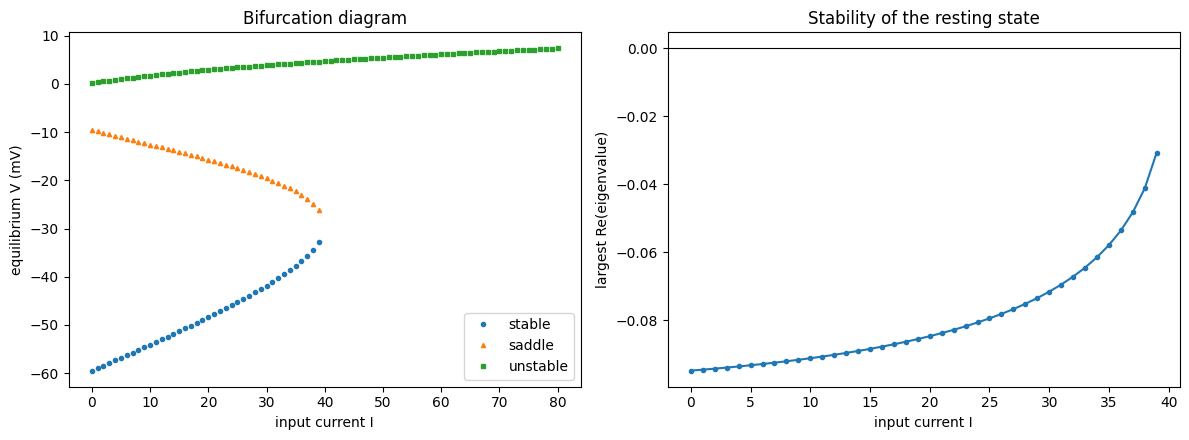

Last input with a stable resting state: 39.0


In [51]:
#find and classify all equilibria for each input current from 0 to 80
I_values = np.arange(0, 80.1, 1.0)                 #input currents to test

rows = []                                          #one entry per equilibrium found
for I in I_values:
    for (V, w) in equilibria(healthy, I):
        eigs = np.linalg.eigvals(jacobian(V, w, I, healthy))
        rows.append((I, V, np.max(np.real(eigs)), classify(eigs)))   #(input, voltage, largest real part, type)

#plot 1: voltage of each equilibrium vs input, marked by type
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
markers = {"stable": "o", "saddle": "^", "unstable": "s"}
for kind in ["stable", "saddle", "unstable"]:
    pts = [(r[0], r[1]) for r in rows if r[3] == kind]             #only this type
    if pts:
        ax[0].plot(*zip(*pts), markers[kind], ms=3, label=kind)
ax[0].set_xlabel("input current I"); ax[0].set_ylabel("equilibrium V (mV)")
ax[0].set_title("Bifurcation diagram"); ax[0].legend()

#plot 2: largest real eigenvalue of the stable rest state, for as long as it exists
rest = [(r[0], r[2]) for r in rows if r[3] == "stable" and r[1] < -20]
ax[1].plot(*zip(*rest), "o-", ms=3)
ax[1].axhline(0, color="k", lw=0.8)                #zero line: crossing it would mean instability
ax[1].set_xlabel("input current I"); ax[1].set_ylabel("largest Re(eigenvalue)")
ax[1].set_title("Stability of the resting state")
fig.tight_layout()
plt.show()

print("Last input with a stable resting state:", max(r[0] for r in rest))

In [52]:
def simulate_input(p, I_func, T, y0, max_step=0.1):
    #like simulate(), but the input current can change over time
    #I_func(t) returns the input current at time t
    def f(t, y):
        V, w = y
        return derivs(V, w, I_func(t), p)
    #smaller max_step (0.1 ms) so the solver doesn't step over a short 5 ms pulse
    sol = solve_ivp(f, (0, T), y0, max_step=max_step, rtol=1e-6, atol=1e-8)
    return sol.t, sol.y[0], sol.y[1]

def count_spikes(t, V, thresh=0.0):
    #count spikes = times V crosses thresh (0 mV) going upward
    above = V >= thresh                       #true where V is above 0 mV
    return int(np.sum(~above[:-1] & above[1:]))   #below at one step, above at the next

def make_two_pulses(gap, I_hold=10.0, amp=300.0, dur=5.0, t1=20.0):
    #returns an input function: steady I_hold, plus two pulses of size amp
    #first pulse starts at t1; second starts gap ms later; each lasts dur ms
    t2 = t1 + gap
    def I_func(t):
        in_pulse = (t1 <= t < t1 + dur) or (t2 <= t < t2 + dur)
        return I_hold + (amp if in_pulse else 0.0)
    return I_func

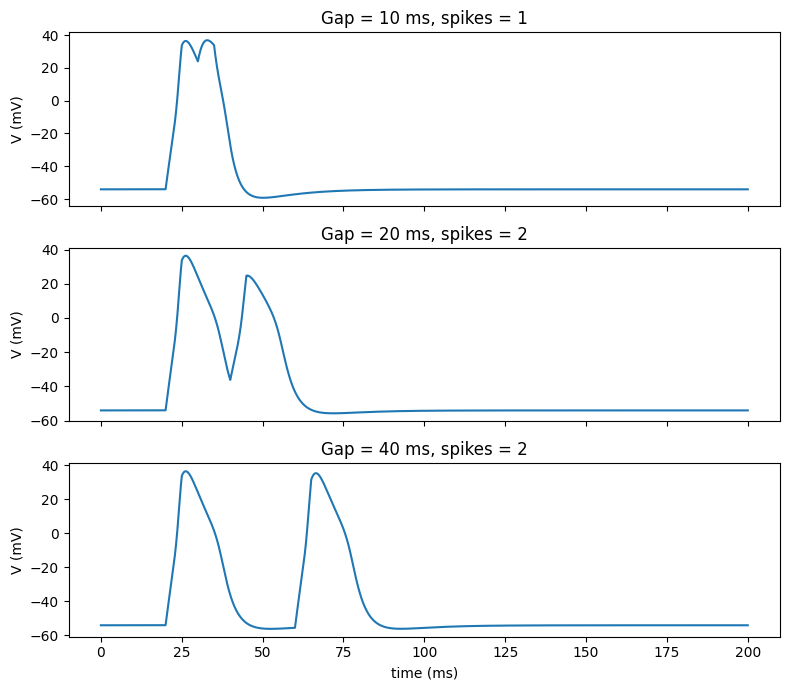

In [53]:
#let the neuron settle at rest with the holding current, so pulses start from a steady state
_, V_rest, w_rest = simulate(healthy, 10.0, T=500.0)
y_rest = (V_rest[-1], w_rest[-1])            #final (V, w) = resting state at I = 10

#look at three gaps: second pulse at 10, 20 and 40 ms after the first
fig, ax = plt.subplots(3, 1, figsize=(8, 7), sharex=True)
for i, gap in enumerate([10, 20, 40]):
    t, V, w = simulate_input(healthy, make_two_pulses(gap), T=200.0, y0=y_rest)
    ax[i].plot(t, V)
    ax[i].set_ylabel("V (mV)")
    ax[i].set_title(f"Gap = {gap} ms, spikes = {count_spikes(t, V)}")
ax[2].set_xlabel("time (ms)")
fig.tight_layout()
plt.show()

Refractory period: about 20 ms


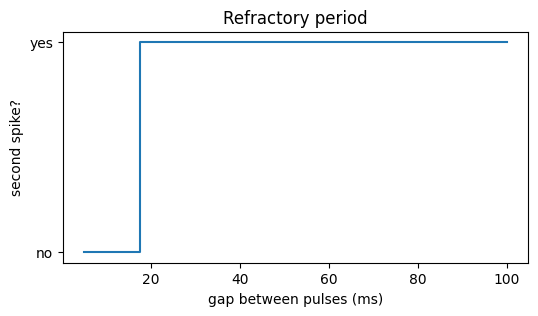

In [54]:
#find the refractory period: try gaps from 5 to 100 ms and check if the second pulse fires
gaps = np.arange(5, 101, 5)
second_fired = []
for gap in gaps:
    t, V, w = simulate_input(healthy, make_two_pulses(gap), T=gap + 170.0, y0=y_rest)
    second_fired.append(count_spikes(t, V) >= 2)      #2 spikes = second pulse worked

second_fired = np.array(second_fired)
print("Refractory period: about", gaps[second_fired][0], "ms")

plt.figure(figsize=(6, 3))
plt.step(gaps, second_fired.astype(int), where="mid")
plt.yticks([0, 1], ["no", "yes"])
plt.xlabel("gap between pulses (ms)"); plt.ylabel("second spike?")
plt.title("Refractory period")
plt.show()

In [55]:
def firing_rate(p, I, T=2000.0, t_start=500.0):
    #steady firing rate (Hz) at constant input I
    #simulate T ms, skip the first t_start ms (settling), count spikes in the rest
    t, V, w = simulate(p, I, T=T)
    keep = t >= t_start                                  #only times after settling
    n_spikes = count_spikes(t[keep], V[keep])
    return 1000.0 * n_spikes / (T - t_start)             #spikes per ms -> spikes per second

def hill(I, fmax, K, n):
    #hill function: S-shaped rise from 0 to fmax, half-max at I = K, steepness n
    return fmax * I**n / (K**n + I**n)

def fit_hill(I_values, rates):
    #fit a Hill function to the rising part of an f-I curve
    #returns fmax, K, n and the input where depolarization block starts
    firing = np.where(rates > 0)[0]                      #indices where the neuron fires
    stop = firing[0]
    while stop + 1 < len(rates) and rates[stop + 1] > 0: #walk forward until firing stops
        stop += 1
    block = I_values[stop + 1] if stop + 1 < len(rates) else None   #first input with no firing
    keep = (I_values > 0) & (np.arange(len(I_values)) <= stop)      #points before the block
    params, _ = curve_fit(hill, I_values[keep], rates[keep],
                          p0=[rates[keep].max(), I_values[firing[0]] + 5, 6],   #starting guesses
                          bounds=([0, 1, 1], [300, 500, 40]))                   #keep values sensible
    fmax, K, n = params
    return fmax, K, n, block

Hill fit: fmax = 24.0 Hz, K = 51.1, n = 5.73
Depolarization block starts at I = 118.0


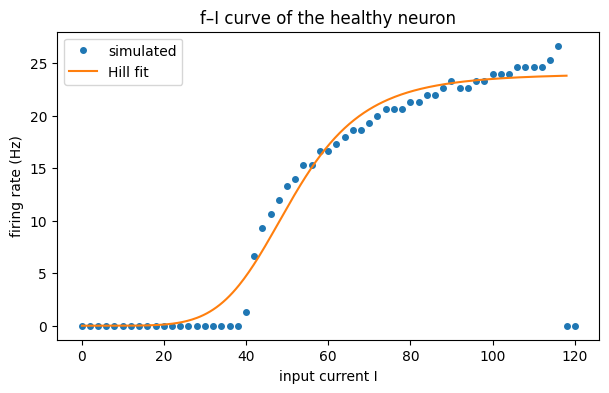

In [56]:
#measure the f-I curve of the healthy neuron (takes about 20-30 seconds)
I_values = np.arange(0, 120.1, 2.0)                      #inputs from 0 to 120 in steps of 2
rates = np.array([firing_rate(healthy, I) for I in I_values])

fmax, K, n, block = fit_hill(I_values, rates)
print(f"Hill fit: fmax = {fmax:.1f} Hz, K = {K:.1f}, n = {n:.2f}")
print(f"Depolarization block starts at I = {block}")

#plot the measured rates and the Hill fit (fit drawn only up to the block)
I_fine = np.linspace(0.1, block, 300)
plt.figure(figsize=(7, 4))
plt.plot(I_values, rates, "o", ms=4, label="simulated")
plt.plot(I_fine, hill(I_fine, fmax, K, n), label="Hill fit")
plt.xlabel("input current I"); plt.ylabel("firing rate (Hz)")
plt.title("f–I curve of the healthy neuron")
plt.legend(); plt.show()

In [57]:
import pandas as pd      #for a results table

#we are basically changing the leak conducance g_L
#this is what happens in Alzheimer's (weakened inhibition = less leak)
#then we measure how the neuron's behaviour changes
#we see if it starts firing at a lower input?
#does it fire faster?
#does it go silent sooner?
def perturb(p, **scales):
    #copy of parameter dict p with some values multiplied
    #example: perturb(healthy, g_L=0.6) -> same as healthy but g_L is 60% of normal
    q = dict(p)                          #copy it, so the original remains unchanged
    for name, factor in scales.items():
        q[name] = p[name] * factor
    return q

def has_stable_rest(p, I):
    #true if there is a stable resting state (below -20 mV) at input I
    for (V, w) in equilibria(p, I):
        if V < -20 and classify(np.linalg.eigvals(jacobian(V, w, I, p))) == "stable":
            return True
    return False

def rheobase(p, lo=0.0, hi=200.0, tol=0.01):
    #find the input where the stable resting state disappears, by bisection
    #keep halving the range [lo, hi] until it is smaller than tol
    while hi - lo > tol:
        mid = (lo + hi) / 2
        if has_stable_rest(p, mid):
            lo = mid          #still resting at mid -> threshold is higher
        else:
            hi = mid          #not resting at mid -> threshold is lower
    return hi

,g_L (% healthy),rheobase,Hill K,Hill n,fmax (Hz),block onset
0,100,40.0,51.1,5.73,24.0,118.0
1,80,28.2,39.4,4.61,23.6,102.0
2,60,17.6,28.9,3.22,23.7,86.0
3,40,8.4,19.7,2.26,23.9,70.0


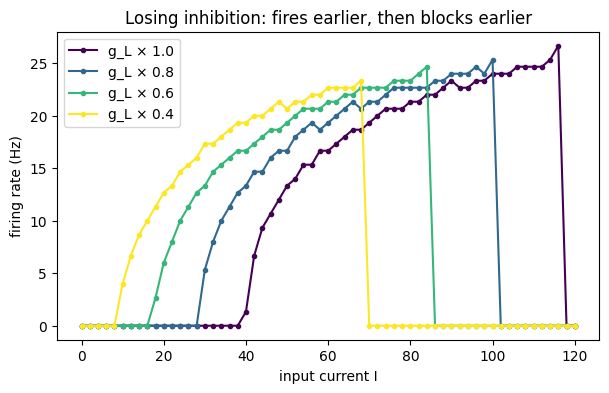

In [58]:
#lower the leak conductance step by step and measure each "disease level"
#this runs 4 f-I curves, so it takes a minute or two.
levels = [1.0, 0.8, 0.6, 0.4]            #g_L as a fraction of healthy
results = []                             #one row of numbers per level
curves = {}                              #f-I curve for each level, for plotting

for s in levels:
    p = perturb(healthy, g_L=s)                                   #diseased parameters
    r = np.array([firing_rate(p, I) for I in I_values])           #f-I curve
    fmax, K, n, block = fit_hill(I_values, r)                     #Hill fit + block onset
    curves[s] = r
    results.append({"g_L (% healthy)": int(s * 100),
                    "rheobase": round(rheobase(p), 1),
                    "Hill K": round(K, 1), "Hill n": round(n, 2),
                    "fmax (Hz)": round(fmax, 1), "block onset": block})

table = pd.DataFrame(results)
display(table)

#plot all f-I curves together, darker = healthier
plt.figure(figsize=(7, 4))
colors = plt.cm.viridis(np.linspace(0, 1, len(levels)))
for s, c in zip(levels, colors):
    plt.plot(I_values, curves[s], "-o", ms=3, color=c, label=f"g_L × {s}")
plt.xlabel("input current I"); plt.ylabel("firing rate (Hz)")
plt.title("Losing inhibition: fires earlier, then blocks earlier")
plt.legend(); plt.show()

In [59]:
#amyloid parameters (dimensionless units)
I_IN  = 30.0    #steady input to the neuron
delta = 0.8     #maximum fraction of inhibition amyloid can remove
K_A   = 1.0     #amyloid level for half the maximum effect
n_A   = 4       #steepness of the amyloid effect
k0    = 0.3     #baseline amyloid production
k1    = 0.1     #extra amyloid production per Hz of firing
gamma = 1.0     #clearance rate

def gL_from_A(amyloid):
    #leak conductance at amyloid level A (Hill-function loss of inhibition)
    loss = delta * amyloid**n_A / (K_A**n_A + amyloid**n_A)       #fraction of inhibition lost, 0 to delta
    return healthy["g_L"] * (1 - loss)

def firing_rate_smooth(p, I, T=2000.0, t_start=500.0):
    #firing rate (Hz) from the average time between spikes, instead of counting spikes
    #changes smoothly with parameters, so there are no staircase steps
    t, V, w = simulate(p, I, T=T)
    crossings = np.where((V[:-1] < 0) & (V[1:] >= 0))[0]   #indices where V crosses 0 mV upward
    spike_times = t[crossings]
    spike_times = spike_times[spike_times >= t_start]      #skip the settling period
    if len(spike_times) < 2:
        return 0.0                                         #fewer than 2 spikes = not firing
    return 1000.0 / np.mean(np.diff(spike_times))          #1 / (average gap in ms), in Hz

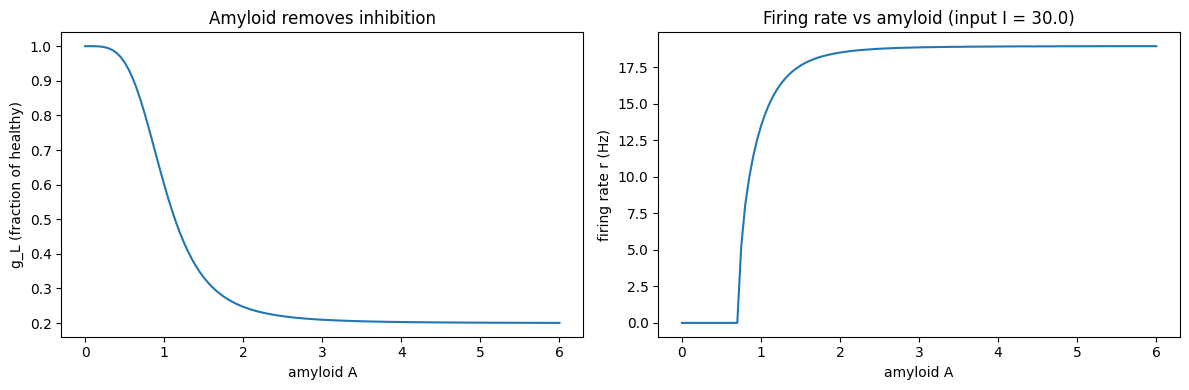

In [60]:
#for each amyloid level, find the neuron's firing rate
A_grid = np.linspace(0, 6, 121)                     #amyloid levels from 0 to 6
r_grid = np.array([firing_rate_smooth(perturb(healthy, g_L=gL_from_A(A) / healthy["g_L"]), I_IN)
                   for A in A_grid])                #firing rate at each amyloid level

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(A_grid, gL_from_A(A_grid) / healthy["g_L"])
ax[0].set_xlabel("amyloid A"); ax[0].set_ylabel("g_L (fraction of healthy)")
ax[0].set_title("Amyloid removes inhibition")
ax[1].plot(A_grid, r_grid)
ax[1].set_xlabel("amyloid A"); ax[1].set_ylabel("firing rate r (Hz)")
ax[1].set_title(f"Firing rate vs amyloid (input I = {I_IN})")
fig.tight_layout(); plt.show()

In [61]:
#fine grid of amyloid levels, with firing rate filled in between the computed points
A_fine = np.linspace(0, 6, 6001)
r_fine = np.interp(A_fine, A_grid, r_grid)

production = k0 + k1 * r_fine          #amyloid made per unit time
clearance  = gamma * A_fine            #amyloid removed per unit time
dAdt = production - clearance          #net rate of change of amyloid

def find_equilibria(dAdt, A):
    #find where dA/dt crosses zero, and label each crossing stable or unstable
    eqs = []
    for i in range(len(A) - 1):
        if dAdt[i] == 0 or dAdt[i] * dAdt[i + 1] < 0:          #zero, or sign change between points
            slope = (dAdt[i + 1] - dAdt[i]) / (A[i + 1] - A[i]) #slope of dA/dt here
            eqs.append((A[i], "stable" if slope < 0 else "unstable"))
    return eqs

equilibria_A = find_equilibria(dAdt, A_fine)
for A_eq, kind in equilibria_A:
    print(f"A = {A_eq:.2f}  ->  {kind}")

A = 0.30  ->  stable
A = 0.74  ->  unstable
A = 2.16  ->  stable


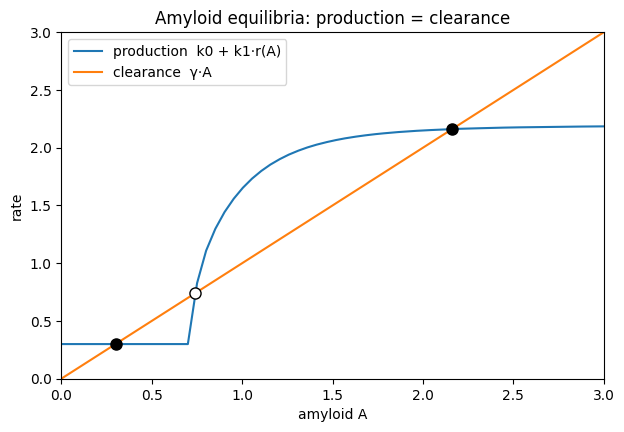

In [62]:
#plot production and clearance and mark the equilibria.
plt.figure(figsize=(7, 4.5))
plt.plot(A_fine, production, label="production  k0 + k1·r(A)")
plt.plot(A_fine, clearance, label="clearance  γ·A")
for A_eq, kind in equilibria_A:
    y = gamma * A_eq
    if kind == "stable":
        plt.plot(A_eq, y, "ko", ms=8)                      #filled = stable
    else:
        plt.plot(A_eq, y, "o", ms=8, mfc="white", mec="k") #open = unstable
plt.xlim(0, 3); plt.ylim(0, 3)
plt.xlabel("amyloid A"); plt.ylabel("rate")
plt.title("Amyloid equilibria: production = clearance")
plt.legend(); plt.show()

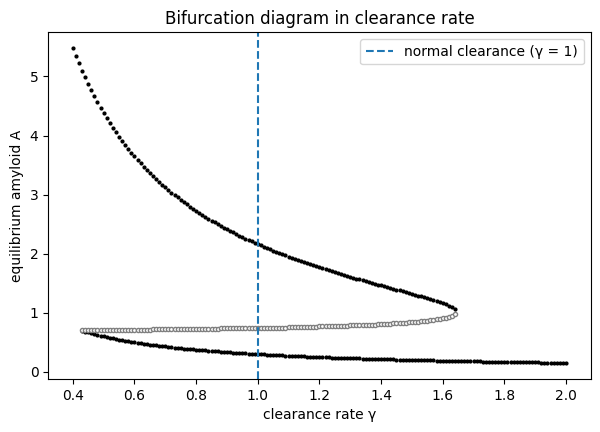

Healthy state exists for  γ ≥ 0.43
Diseased state exists for γ ≤ 1.64


In [63]:
#find all equilibria for many clearance rates
gammas = np.arange(0.4, 2.001, 0.01)
points = []                                         #(gamma, A, stable/unstable)
for g in gammas:
    dAdt_g = k0 + k1 * r_fine - g * A_fine          #same production, different clearance
    for A_eq, kind in find_equilibria(dAdt_g, A_fine):
        points.append((g, A_eq, kind))

#bifurcation diagram: filled = stable, open = unstable
plt.figure(figsize=(7, 4.5))
for g, A_eq, kind in points:
    if kind == "stable":
        plt.plot(g, A_eq, "k.", ms=4)
    else:
        plt.plot(g, A_eq, "o", ms=3, mfc="white", mec="gray")
plt.axvline(1.0, color="C0", ls="--", label="normal clearance (γ = 1)")
plt.xlabel("clearance rate γ"); plt.ylabel("equilibrium amyloid A")
plt.title("Bifurcation diagram in clearance rate")
plt.legend(); plt.show()

#where does each stable state exist?
healthy_g  = [g for g, A_eq, kind in points if kind == "stable" and A_eq < 0.7]   #neuron silent
diseased_g = [g for g, A_eq, kind in points if kind == "stable" and A_eq > 0.7]   #neuron firing
print(f"Healthy state exists for  γ ≥ {min(healthy_g):.2f}")
print(f"Diseased state exists for γ ≤ {max(diseased_g):.2f}")

In [64]:
def gamma_schedule(t, restore_time):
    #clearance rate at time t for one "patient"
    #restore_time = when clearance returns to normal after the failure
    if t < 20:            return 1.0     #healthy
    if t < restore_time:  return 0.3     #clearance failure
    if t < 80:            return 1.0     #back to normal
    if t < 120:           return 1.8     #strong drug
    return 1.0                           #drug stopped

def simulate_amyloid(restore_time, T=160.0, A0=0.3):
    #simulate amyloid over time, starting at the healthy level A0
    def f(t, y):
        A = y[0]
        r = np.interp(A, A_grid, r_grid)                 #neuron's firing rate at this amyloid level
        return [k0 + k1 * r - gamma_schedule(t, restore_time) * A]
    sol = solve_ivp(f, (0, T), [A0], max_step=0.1)      #small steps so sudden changes in γ are caught
    return sol.t, sol.y[0]

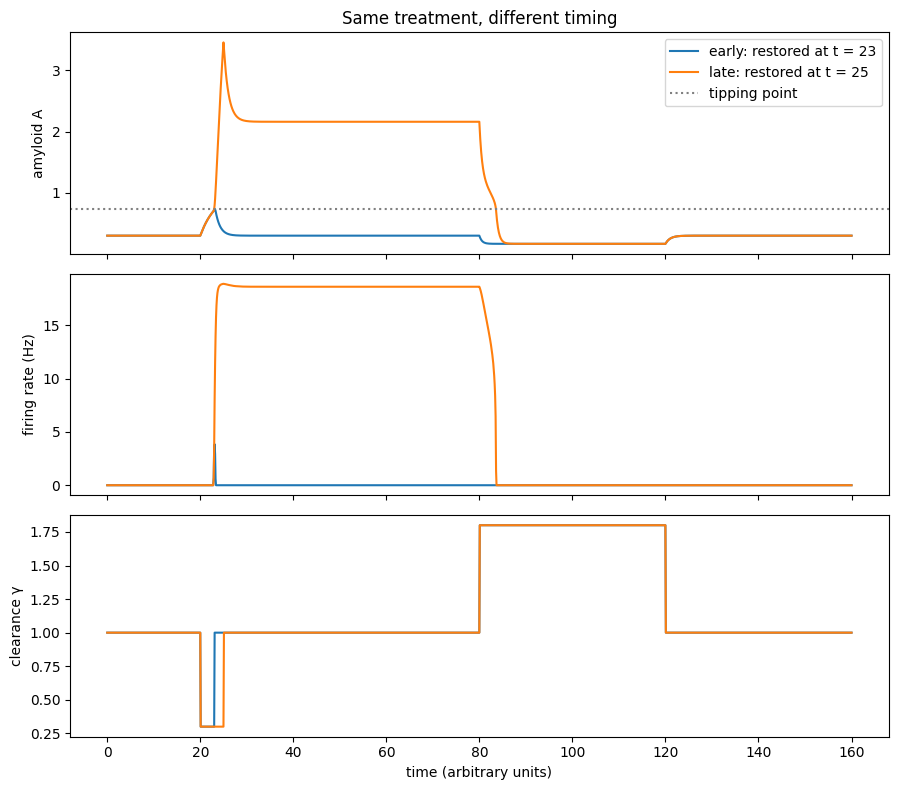

In [65]:
fig, ax = plt.subplots(3, 1, figsize=(9, 8), sharex=True)
for restore_time, label in [(23, "early: restored at t = 23"), (25, "late: restored at t = 25")]:
    t, A = simulate_amyloid(restore_time)
    ax[0].plot(t, A, label=label)                                          #amyloid
    ax[1].plot(t, np.interp(A, A_grid, r_grid))                            #firing rate
    ax[2].plot(t, [gamma_schedule(ti, restore_time) for ti in t])          #clearance

ax[0].axhline(0.74, color="gray", ls=":", label="tipping point")
ax[0].set_ylabel("amyloid A"); ax[0].legend()
ax[1].set_ylabel("firing rate (Hz)")
ax[2].set_ylabel("clearance γ"); ax[2].set_xlabel("time (arbitrary units)")
ax[0].set_title("Same treatment, different timing")
fig.tight_layout(); plt.show()

In [66]:
#firing rate vs fraction of healthy leak remaining (computed once, about 20 seconds).
frac_grid = np.linspace(0.05, 1.0, 96)                     #g_L from 5% to 100% of healthy
r_frac = np.array([firing_rate_smooth(perturb(healthy, g_L=f), I_IN) for f in frac_grid])

A_wide = np.linspace(0, 15, 7501)                          #wider amyloid range, since some settings push A higher

def bistable_range(q):
    #for amyloid parameters q, return (gamma_low, gamma_high): the clearance range where
    #both a healthy and a diseased stable state exist. none if never bistable
    frac = 1 - q["delta"] * A_wide**q["n_A"] / (q["K_A"]**q["n_A"] + A_wide**q["n_A"])   #g_L fraction at each A
    production = q["k0"] + q["k1"] * np.interp(frac, frac_grid, r_frac)                   #uses the shortcut
    bistable_gammas = []
    for g in np.arange(0.05, 4.001, 0.01):
        stable = [A for A, kind in find_equilibria(production - g * A_wide, A_wide) if kind == "stable"]
        if len(stable) >= 2:                               #two stable states = bistable
            bistable_gammas.append(g)
    if not bistable_gammas:
        return None
    return round(min(bistable_gammas), 2), round(max(bistable_gammas), 2)

base = dict(k0=0.3, k1=0.1, delta=0.8, K_A=1.0, n_A=4)
print("Original parameters:", bistable_range(base))       #should give (0.43, 1.64)

Original parameters: (np.float64(0.43), np.float64(1.64))


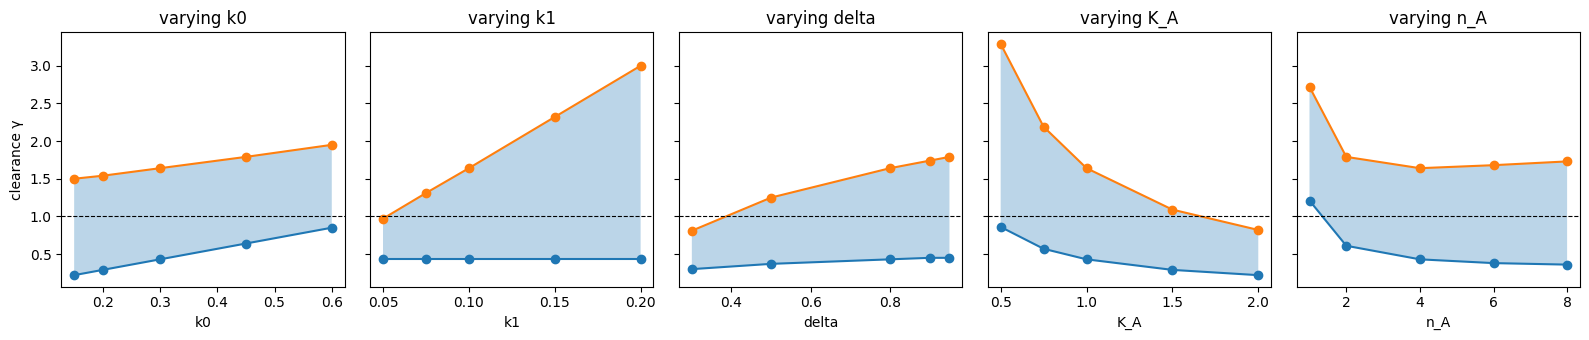

,parameter,value,gamma_low,gamma_high
0,k0,0.150,0.22,1.50
1,k0,0.200,0.29,1.54
2,k0,0.300,0.43,1.64
3,k0,0.450,0.64,1.79
4,k0,0.600,0.85,1.95
5,k1,0.050,0.43,0.97
6,k1,0.075,0.43,1.31
7,k1,0.100,0.43,1.64
8,k1,0.150,0.43,2.32
9,k1,0.200,0.43,3.00


In [67]:
#vary each parameter while keeping the others at their original values.
tests = {"k0":    [0.15, 0.2, 0.3, 0.45, 0.6],
         "k1":    [0.05, 0.075, 0.1, 0.15, 0.2],
         "delta": [0.3, 0.5, 0.8, 0.9, 0.95],
         "K_A":   [0.5, 0.75, 1.0, 1.5, 2.0],
         "n_A":   [1, 2, 4, 6, 8]}

rows = []
fig, ax = plt.subplots(1, 5, figsize=(16, 3.5), sharey=True)
for i, (name, values) in enumerate(tests.items()):
    lows, highs = [], []
    for v in values:
        q = dict(base); q[name] = v                        #change one parameter
        rng = bistable_range(q)
        rows.append({"parameter": name, "value": v,
                     "gamma_low": rng[0] if rng else None, "gamma_high": rng[1] if rng else None})
        lows.append(rng[0] if rng else np.nan); highs.append(rng[1] if rng else np.nan)
    ax[i].fill_between(values, lows, highs, alpha=0.3, label="bistable")   #shaded = both states exist
    ax[i].plot(values, lows, "o-"); ax[i].plot(values, highs, "o-")
    ax[i].axhline(1.0, color="k", ls="--", lw=0.8)                         #normal clearance
    ax[i].set_xlabel(name); ax[i].set_title(f"varying {name}")
ax[0].set_ylabel("clearance γ")
fig.tight_layout(); plt.show()

display(pd.DataFrame(rows))

In [68]:
import requests

API = "https://api.brain-map.org/api/v2/data/query.json"

def allen_query(criteria):
    #send a query to the Allen Brain Map API and return the results as a table
    response = requests.get(API, params={"criteria": criteria}, timeout=120)
    response.raise_for_status()                    #stop with an error if the request failed
    data = response.json()
    if not data.get("success", False):             #the API reports its own errors this way
        raise RuntimeError(data.get("msg"))
    return pd.DataFrame(data["msg"])               #results -> table

#download the list of all recorded cells
cells = allen_query("model::ApiCellTypesSpecimenDetail,rma::options[num_rows$eqall]")
print(len(cells), "cells downloaded")
print(cells.columns.tolist())                      #column names, to check what information we have

2333 cells downloaded
['cell_reporter_status', 'csl__normalized_depth', 'csl__x', 'csl__y', 'csl__z', 'donor__age', 'donor__disease_state', 'donor__id', 'donor__name', 'donor__race', 'donor__sex', 'donor__species', 'donor__years_of_seizure_history', 'ef__adaptation', 'ef__avg_firing_rate', 'ef__avg_isi', 'ef__f_i_curve_slope', 'ef__fast_trough_v_long_square', 'ef__peak_t_ramp', 'ef__ri', 'ef__tau', 'ef__threshold_i_long_square', 'ef__upstroke_downstroke_ratio_long_square', 'ef__vrest', 'ephys_inst_thresh_thumb_path', 'ephys_thumb_path', 'erwkf__id', 'line_name', 'm__biophys', 'm__biophys_all_active', 'm__biophys_perisomatic', 'm__glif', 'morph_thumb_path', 'nr__average_contraction', 'nr__average_parent_daughter_ratio', 'nr__max_euclidean_distance', 'nr__number_bifurcations', 'nr__number_stems', 'nr__reconstruction_type', 'nrwkf__id', 'si__height', 'si__path', 'si__width', 'specimen__hemisphere', 'specimen__id', 'specimen__name', 'structure__acronym', 'structure__id', 'structure__layer'

In [69]:
#keep only mouse, spiny (excitatory), layer 5 neurons that have a measured rheobase
mouse_l5 = cells[(cells["donor__species"] == "Mus musculus")
                 & (cells["tag__dendrite_type"] == "spiny")
                 & (cells["structure__layer"].astype(str) == "5")
                 & cells["ef__threshold_i_long_square"].notna()]
mouse_l5 = mouse_l5.sort_values("specimen__id")           #fixed order, so the choice is reproducible
print(len(mouse_l5), "mouse layer 5 excitatory neurons")

#show a few candidates with their Allen-measured rheobase (pA) and f-I slope (Hz/pA)
display(mouse_l5[["specimen__id", "structure__acronym", "ef__threshold_i_long_square",
                  "ef__f_i_curve_slope"]].head(10))

#download the sweep list for the first candidate.
cell_id = int(mouse_l5["specimen__id"].iloc[0])
sweeps = allen_query(f"model::EphysSweep,rma::criteria,[specimen_id$eq{cell_id}],rma::options[num_rows$eqall]")
print("Cell", cell_id, "has", len(sweeps), "sweeps")
print(sweeps.columns.tolist())

302 mouse layer 5 excitatory neurons


,specimen__id,structure__acronym,ef__threshold_i_long_square,ef__f_i_curve_slope
1886,313860745,VISp5,59.999996,0.182362
1258,314617802,VISp5,50.000000,0.193182
1055,314800921,VISl5,110.000000,0.073476
46,314804042,VISp5,90.000000,0.154762
947,314822529,VISp5,190.000000,0.134139
2175,314831019,VISp5,90.000000,0.155724
714,320654829,VISp5,249.999985,0.117905
1023,320836481,VISpor5,90.000000,0.111111
1079,321013314,VISp5,90.000000,0.142837
198,322762730,VISp5,130.000000,0.162266


Cell 313860745 has 52 sweeps
['bridge_balance_mohm', 'id', 'leak_pa', 'num_spikes', 'peak_deflection', 'post_noise_rms_mv', 'post_vm_mv', 'pre_noise_rms_mv', 'pre_vm_mv', 'slow_noise_rms_mv', 'slow_vm_mv', 'specimen_id', 'stimulus_absolute_amplitude', 'stimulus_description', 'stimulus_duration', 'stimulus_interval', 'stimulus_name', 'stimulus_relative_amplitude', 'stimulus_start_time', 'stimulus_units', 'sweep_number', 'vm_delta_mv']


stimulus_name
Long Square                    19
Short Square                   17
Test                            5
Ramp                            3
Noise 1                         3
Noise 2                         3
Square - 0.5ms Subthreshold     2
Name: count, dtype: int64
Step durations: [0.999995]


,amp_pA,rate_hz
0,10.0,0.000000
1,30.0,0.000000
2,50.0,0.000000
3,60.0,2.000010
4,70.0,7.000035
5,90.0,11.000055
6,110.0,15.000075
7,130.0,19.000095
8,150.0,23.000115
9,170.0,26.000130


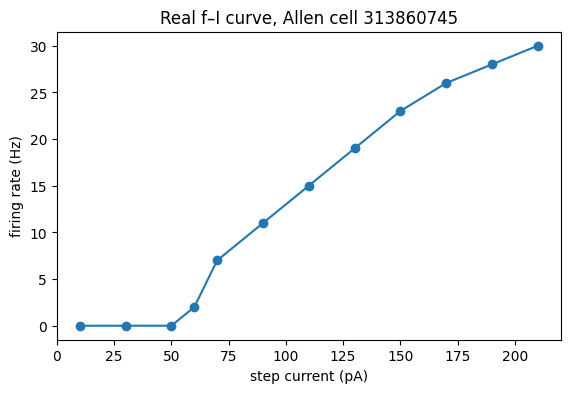

In [70]:
#what kinds of stimuli were applied to this cell?
print(sweeps["stimulus_name"].value_counts())

def get_fI(sweeps):
    #turn a cell's sweep table into an f-I curve: current (pA) vs firing rate (Hz).
    ls = sweeps[(sweeps["stimulus_name"] == "Long Square")          #only the 1-second current steps
                & (sweeps["stimulus_absolute_amplitude"] >= 0)]     #skip negative (hyperpolarizing) steps
    duration = ls["stimulus_duration"].astype(float)
    if duration.max() > 100:                                         #if duration is in ms, convert to seconds
        duration = duration / 1000
    rate = ls["num_spikes"].fillna(0).astype(float) / duration      #spikes per second; no spikes recorded = 0
    fI = pd.DataFrame({"amp_pA": ls["stimulus_absolute_amplitude"].astype(float).round(),
                       "rate_hz": rate})
    return fI.groupby("amp_pA", as_index=False).mean()               #average repeated amplitudes

fI_data = get_fI(sweeps)
print("Step durations:", sweeps.loc[sweeps["stimulus_name"] == "Long Square", "stimulus_duration"].unique())
display(fI_data)

plt.figure(figsize=(6.5, 4))
plt.plot(fI_data["amp_pA"], fI_data["rate_hz"], "o-")
plt.xlabel("step current (pA)"); plt.ylabel("firing rate (Hz)")
plt.title(f"Real f–I curve, Allen cell {cell_id}")
plt.show()

In [71]:
def simulate_many(p, I_values, T=1000.0, y0=(-60.0, 0.0), dt=0.1):
    #simulate several copies of the neuron at once, each with its own constant input
    #same results as calling simulate() for each input, but much faster.
    I = np.asarray(I_values, float)
    N = len(I)                                          #number of neurons
    def f(t, y):
        #y holds all voltages first, then all w values: [V1..VN, w1..wN]
        dV, dw = derivs(y[:N], y[N:], I, p)              #derivs works on whole arrays
        return np.concatenate([dV, dw])
    y_init = np.concatenate([np.full(N, y0[0]), np.full(N, y0[1])])   #every neuron starts at y0
    sol = solve_ivp(f, (0, T), y_init, t_eval=np.arange(0, T, dt),     #report values every 0.1 ms
                    max_step=0.5, rtol=1e-6, atol=1e-8)
    return sol.t, sol.y[:N]                             #times, and one voltage trace per neuron


from scipy.optimize import minimize

def rest_point(p):
    #the resting state (V, w) with no input: the lowest-voltage equilibrium at I = 0
    return min(equilibria(p, 0.0), key=lambda e: e[0])

def model_rates_pA(s, phi, amps_pA, base=healthy, T=1000.0):
    #model firing rate (Hz) for 1-second current steps given in pA, starting from rest.
    p = dict(base, phi=phi)
    y0 = rest_point(p)
    t, V_all = simulate_many(p, np.asarray(amps_pA) / s, T=T, y0=y0)   # all steps at once
    rates = []
    for V in V_all:                                                     # one voltage trace per step
        crossings = np.where((V[:-1] < 0) & (V[1:] >= 0))[0]
        n = len(crossings)
        if n >= 2:
            spike_times = t[crossings]
            last_gap = spike_times[-1] - spike_times[-2]
            n += min((T - spike_times[-1]) / last_gap, 0.999)
        rates.append(n * 1000.0 / T)
    return np.array(rates)

def fit_fI(amps, rates, base=healthy):
    #fit s and phi so the model's f-I curve matches measured (amps, rates)
    amps, rates = np.asarray(amps, float), np.asarray(rates, float)

    #starting guess for s: measured threshold / model threshold
    first = np.argmax(rates > 0)                                    #first step where the cell fired
    threshold_pA = (amps[first] + amps[max(first - 1, 0)]) / 2      #halfway between last silent and first firing step
    s0 = threshold_pA / rheobase(base)

    def cost(s, phi):
        return np.sum((model_rates_pA(s, phi, amps, base) - rates) ** 2)   #sum of squared errors

    #try a few phi values with s0, keep the best as the starting point.
    phis = [0.03, 0.05, 0.08, 0.12, 0.2, 0.3]
    phi0 = phis[np.argmin([cost(s0, ph) for ph in phis])]

    #refine both. searching over log(s) and log(phi) keeps them positive
    result = minimize(lambda x: cost(np.exp(x[0]), np.exp(x[1])), np.log([s0, phi0]),
                      method="Nelder-Mead", options=dict(maxiter=60, xatol=1e-3, fatol=1e-2))
    s, phi = np.exp(result.x)
    rmse = np.sqrt(result.fun / len(amps))                           #typical error per point, in Hz
    return s, phi, rmse

In [73]:
#test: can the fit recover values we already know?
amps_test = np.arange(0, 301, 20)                     #fake current steps, 0 to 300 pA
s_true, phi_true = 3.5, 0.10
fake_rates = np.round(model_rates_pA(s_true, phi_true, amps_test))   #whole spike counts, like real data

s_fit, phi_fit, rmse = fit_fI(amps_test, fake_rates)
print(f"true:   s = {s_true:.2f}, phi = {phi_true:.3f}")
print(f"fitted: s = {s_fit:.2f}, phi = {phi_fit:.3f}   (error {rmse:.2f} Hz)")

true:   s = 3.50, phi = 0.100
fitted: s = 3.50, phi = 0.101   (error 0.19 Hz)


In [74]:
%time r = model_rates_pA(3.5, 0.1, amps_test)

CPU times: user 3.15 s, sys: 12 ms, total: 3.16 s
Wall time: 3.22 s


Cell 313860745: s = 2.05 pA per model unit, phi = 0.087, error = 2.3 Hz
Model threshold: 82 pA   (Allen measured: 60 pA)


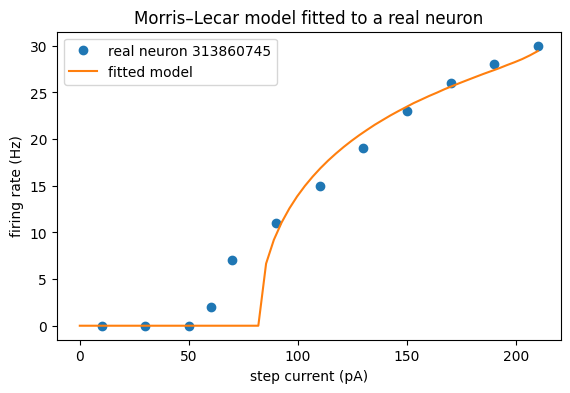

In [75]:
#fit the model to the real Allen cell's f-I curve
s_fit, phi_fit, rmse = fit_fI(fI_data["amp_pA"], fI_data["rate_hz"])

fitted = dict(healthy, phi=phi_fit)               #healthy parameters, with the fitted phi
print(f"Cell {cell_id}: s = {s_fit:.2f} pA per model unit, phi = {phi_fit:.3f}, error = {rmse:.1f} Hz")
print(f"Model threshold: {rheobase(fitted) * s_fit:.0f} pA   (Allen measured: 60 pA)")

#compare the fitted model with the real data
amps_fine = np.linspace(0, fI_data["amp_pA"].max(), 60)
plt.figure(figsize=(6.5, 4))
plt.plot(fI_data["amp_pA"], fI_data["rate_hz"], "o", label=f"real neuron {cell_id}")
plt.plot(amps_fine, model_rates_pA(s_fit, phi_fit, amps_fine), label="fitted model")
plt.xlabel("step current (pA)"); plt.ylabel("firing rate (Hz)")
plt.title("Morris–Lecar model fitted to a real neuron")
plt.legend(); plt.show()

In [76]:
#firing rate vs amyloid for the neuron fitted to real data (about 30 seconds)
r_grid_fit = np.array([firing_rate_smooth(perturb(fitted, g_L=gL_from_A(A) / healthy["g_L"]), I_IN)
                       for A in A_grid])
r_fine_fit = np.interp(A_fine, A_grid, r_grid_fit)

def summarize(r_fine, label):
    #print the equilibria at normal clearance, and the clearance range where the system is bistable
    eqs = find_equilibria(k0 + k1 * r_fine - 1.0 * A_fine, A_fine)
    bistable = [g for g in np.arange(0.4, 2.5, 0.01)
                if sum(kind == "stable" for _, kind in
                       find_equilibria(k0 + k1 * r_fine - g * A_fine, A_fine)) >= 2]   #two stable states
    print(label)
    print("  equilibria at γ = 1:", [(round(A, 2), kind) for A, kind in eqs])
    print(f"  bistable for γ from {min(bistable):.2f} to {max(bistable):.2f}")

summarize(r_fine, "Textbook neuron")
summarize(r_fine_fit, "Neuron fitted to Allen data")

Textbook neuron
  equilibria at γ = 1: [(np.float64(0.3), 'stable'), (np.float64(0.74), 'unstable'), (np.float64(2.16), 'stable')]
  bistable for γ from 0.43 to 1.64
Neuron fitted to Allen data
  equilibria at γ = 1: [(np.float64(0.3), 'stable'), (np.float64(0.74), 'unstable'), (np.float64(2.53), 'stable')]
  bistable for γ from 0.43 to 1.81
